# Определение частей речи (POS-tagging) для русского текста

Программа получает предложение и для каждого слова выводит его часть речи.

1. Тексты для обучения — те же, что в задании 1: `examples/Маша и медведь.txt` и `examples/вирус.txt`.
2. Разметка: каждое слово размечается анализатором `pymorphy3` (берётся самый вероятный разбор).
3. Модели:
   - **CNN**: свёртка по символам слова (ядра 3, 4, 5) -> свёртка по словам предложения -> полносвязные слои;
   - **RNN**: BiLSTM по символам слова -> BiLSTM по словам предложения -> выходной слой.
4. Длина слова (`MAX_CHARS`) и число слов в предложении (`MAX_WORDS`) фиксированы, короткие дополняются `PAD`.
   Для каждого слова модель выдаёт вектор вероятностей по всем частям речи.

In [1]:
import os
import re
import json
import random

import numpy as np
import matplotlib.pyplot as plt
import pymorphy3
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix


SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

BASE_DIR = os.getcwd()
NLP_DIR = os.path.dirname(BASE_DIR)
TEXT_FILES = [
    os.path.join(NLP_DIR, 'examples', 'Маша и медведь.txt'),
    os.path.join(NLP_DIR, 'examples', 'вирус.txt'),
]
MODEL_DIR = os.path.join(BASE_DIR, 'models')


## Параметры

In [2]:
MAX_WORDS = 30          # фиксированное количество слов в предложении
MAX_CHARS = 20          # фиксированная длина слова в символах
CHAR_EMB_DIM = 32       # размерность символьного представления
N_FILTERS = 64          # фильтров на каждое ядро в CNN
KERNEL_SIZES = (3, 4, 5)
EPOCHS = 100
BATCH_SIZE = 32

TOKEN_RE = re.compile(r'[A-Za-zА-Яа-яЁё]+|\d+|[^\w\s]')
SENT_SPLIT_RE = re.compile(r'(?<=[.!?…])\s+|\n+')

TAGS = ['NOUN', 'VERB', 'ADJ', 'ADV', 'PRON', 'NUM', 'PREP', 'CONJ', 'PART', 'INTJ', 'PUNCT', 'X']
TAG2ID = {t: i for i, t in enumerate(TAGS)}
PAD_ID, UNK_ID = 0, 1
PAD_LABEL = -1          # метка для дополненных слов, в loss и accuracy не учитывается


## Разметка текста анализатором pymorphy3

Теги OpenCorpora объединяются в 12 укрупнённых частей речи.

In [3]:
POS_MAP = {
    'NOUN': 'NOUN',
    'ADJF': 'ADJ', 'ADJS': 'ADJ',
    'VERB': 'VERB', 'INFN': 'VERB', 'PRTF': 'VERB', 'PRTS': 'VERB', 'GRND': 'VERB',
    'ADVB': 'ADV', 'COMP': 'ADV', 'PRED': 'ADV',
    'NUMR': 'NUM',
    'NPRO': 'PRON',
    'PREP': 'PREP',
    'CONJ': 'CONJ',
    'PRCL': 'PART',
    'INTJ': 'INTJ',
}

morph = pymorphy3.MorphAnalyzer()


def pos_tag(word):
    if re.fullmatch(r'\d+', word):
        return 'NUM'
    if not re.search(r'[А-Яа-яЁё]', word):
        return 'X' if re.search(r'[A-Za-z]', word) else 'PUNCT'
    return POS_MAP.get(morph.parse(word)[0].tag.POS, 'X')


def load_sentences(paths):
    sentences = []
    for path in paths:
        with open(path, encoding='utf-8') as f:
            text = f.read()
        for sent in SENT_SPLIT_RE.split(text):
            tokens = TOKEN_RE.findall(sent)
            if tokens:
                sentences.append(tokens)
    return sentences


sentences = load_sentences(TEXT_FILES)
tagged_sentences = [[(w, pos_tag(w)) for w in s] for s in sentences]

print(f'Предложений: {len(tagged_sentences)}, токенов: {sum(len(s) for s in tagged_sentences)}')
print('Пример разметки:')
print(' '.join(f'{w}/{t}' for w, t in tagged_sentences[0]))


Предложений: 211, токенов: 3222
Пример разметки:
Жили/VERB -/PUNCT были/VERB дедушка/NOUN да/PART бабушка/NOUN ./PUNCT


## Разбиение на выборки

Делим по предложениям, чтобы одно и то же предложение не попало одновременно в train и test.
Длинные предложения режем на куски по `MAX_WORDS` слов.

In [4]:
train_sents, test_sents = train_test_split(tagged_sentences, test_size=0.15, random_state=SEED)
train_sents, val_sents = train_test_split(train_sents, test_size=0.15 / 0.85, random_state=SEED)


def to_chunks(sents):
    chunks = []
    for s in sents:
        for i in range(0, len(s), MAX_WORDS):
            chunks.append(s[i:i + MAX_WORDS])
    return chunks


train_chunks = to_chunks(train_sents)
val_chunks = to_chunks(val_sents)
test_chunks = to_chunks(test_sents)
print(f'Train: {len(train_chunks)}, Validation: {len(val_chunks)}, Test: {len(test_chunks)} фрагментов')


Train: 157, Validation: 35, Test: 34 фрагментов


## Кодирование

Символы кодируются индексами (embedding-слой эквивалентен OHE + линейный слой без смещения).
Словарь строится только по обучающей выборке, неизвестные символы получают `UNK`.

In [5]:
train_chars = sorted({c for chunk in train_chunks for w, _ in chunk for c in w})
char2id = {c: i + 2 for i, c in enumerate(train_chars)}
N_CHARS = len(char2id) + 2
print(f'Размер символьного словаря: {N_CHARS}')


def encode_words(chunks, char2id):
    X = np.zeros((len(chunks), MAX_WORDS, MAX_CHARS), dtype='int32')
    for i, chunk in enumerate(chunks):
        for j, word in enumerate(chunk):
            for k, c in enumerate(word[:MAX_CHARS]):
                X[i, j, k] = char2id.get(c, UNK_ID)
    return X


def encode_tags(chunks):
    y = np.full((len(chunks), MAX_WORDS), PAD_LABEL, dtype='int32')
    for i, chunk in enumerate(chunks):
        for j, (_, tag) in enumerate(chunk):
            y[i, j] = TAG2ID[tag]
    return y


def strip_tags(chunks):
    return [[w for w, _ in chunk] for chunk in chunks]


X_train = encode_words(strip_tags(train_chunks), char2id)
X_val = encode_words(strip_tags(val_chunks), char2id)
X_test = encode_words(strip_tags(test_chunks), char2id)
y_train = encode_tags(train_chunks)
y_val = encode_tags(val_chunks)
y_test = encode_tags(test_chunks)
print(f'X_train: {X_train.shape}  (фрагменты, слова, символы)')


Размер символьного словаря: 92
X_train: (157, 30, 20)  (фрагменты, слова, символы)


## Модель 1: сверточная сеть (CNN)

- `Embedding` по символам слова;
- одномерные свёртки по символам с ядрами 3, 4, 5 и `GlobalMaxPooling` -> вектор слова;
- одномерная свёртка по словам предложения;
- полносвязные слои и `softmax` для каждого слова.

In [6]:
def build_cnn(n_chars, n_tags):
    char_in = keras.Input(shape=(MAX_CHARS,), dtype='int32')
    x = layers.Embedding(n_chars, CHAR_EMB_DIM)(char_in)
    pooled = []
    for k in KERNEL_SIZES:
        c = layers.Conv1D(N_FILTERS, k, activation='relu', padding='same')(x)
        pooled.append(layers.GlobalMaxPooling1D()(c))
    word_vec = layers.Dropout(0.3)(layers.Concatenate()(pooled))
    word_encoder = keras.Model(char_in, word_vec, name='char_cnn')

    sent_in = keras.Input(shape=(MAX_WORDS, MAX_CHARS), dtype='int32')
    h = layers.TimeDistributed(word_encoder)(sent_in)
    h = layers.Conv1D(128, 3, activation='relu', padding='same')(h)
    h = layers.TimeDistributed(layers.Dense(64, activation='relu'))(h)
    h = layers.Dropout(0.3)(h)
    out = layers.TimeDistributed(layers.Dense(n_tags, activation='softmax'))(h)
    return keras.Model(sent_in, out, name='cnn_pos')


cnn_model = build_cnn(N_CHARS, len(TAGS))
cnn_model.summary()


Model: "cnn_pos"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 30, 20)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 30, 192)        │        27,712 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 30, 128)        │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 30, 64)         │         8,256 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_2              │ (None, 30, 12)         │           780 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,604 (432.05 KB)

 Trainable params: 110,604 (432.05 KB)

 Non-trainable params: 0 (0.00 B)

## Модель 2: рекуррентная сеть (RNN)

- `Embedding` по символам с маскированием `PAD`;
- `Bidirectional(LSTM)` по символам слова -> вектор слова;
- `Bidirectional(LSTM)` по словам предложения;
- `softmax` для каждого слова.

In [7]:
def build_rnn(n_chars, n_tags):
    char_in = keras.Input(shape=(MAX_CHARS,), dtype='int32')
    x = layers.Embedding(n_chars, CHAR_EMB_DIM, mask_zero=True)(char_in)
    word_vec = layers.Bidirectional(layers.LSTM(64))(x)
    word_encoder = keras.Model(char_in, word_vec, name='char_rnn')

    sent_in = keras.Input(shape=(MAX_WORDS, MAX_CHARS), dtype='int32')
    h = layers.TimeDistributed(word_encoder)(sent_in)
    h = layers.Bidirectional(layers.LSTM(128, return_sequences=True))(h)
    h = layers.Dropout(0.3)(h)
    out = layers.TimeDistributed(layers.Dense(n_tags, activation='softmax'))(h)
    return keras.Model(sent_in, out, name='rnn_pos')


rnn_model = build_rnn(N_CHARS, len(TAGS))
rnn_model.summary()


Model: "rnn_pos"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 30, 20)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_3              │ (None, 30, 128)        │        52,608 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 30, 256)        │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 30, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_4              │ (None, 30, 12)         │         3,084 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 318,860 (1.22 MB)

 Trainable params: 318,860 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

## Обучение

Потери и accuracy считаются только по реальным словам (метка `PAD_LABEL` игнорируется).

In [8]:
def masked_loss(y_true, y_pred):
    mask = tf.cast(y_true != PAD_LABEL, tf.float32)
    ce = keras.losses.sparse_categorical_crossentropy(tf.maximum(y_true, 0), y_pred)
    return tf.reduce_sum(ce * mask) / tf.maximum(tf.reduce_sum(mask), 1.0)


def masked_accuracy(y_true, y_pred):
    mask = tf.cast(y_true != PAD_LABEL, tf.float32)
    hit = tf.cast(tf.equal(tf.maximum(y_true, 0), tf.argmax(y_pred, axis=-1, output_type=tf.int32)), tf.float32)
    return tf.reduce_sum(hit * mask) / tf.maximum(tf.reduce_sum(mask), 1.0)


def train(model, name):
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss=masked_loss,
        metrics=[masked_accuracy],
    )
    early_stop = keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=8, restore_best_weights=True, verbose=1,
    )
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stop],
        verbose=2,
    )
    os.makedirs(MODEL_DIR, exist_ok=True)
    model.save(os.path.join(MODEL_DIR, f'{name}.keras'))
    return history


cnn_history = train(cnn_model, 'cnn_pos')
rnn_history = train(rnn_model, 'rnn_pos')

with open(os.path.join(MODEL_DIR, 'char2id.json'), 'w', encoding='utf-8') as f:
    json.dump(char2id, f, ensure_ascii=False, indent=1)


Epoch 1/100
5/5 - 10s - 2s/step - loss: 2.3944 - masked_accuracy: 0.2536 - val_loss: 2.1982 - val_masked_accuracy: 0.2699
Epoch 2/100
5/5 - 0s - 34ms/step - loss: 2.1589 - masked_accuracy: 0.2959 - val_loss: 2.0372 - val_masked_accuracy: 0.2699
Epoch 3/100
5/5 - 0s - 34ms/step - loss: 2.0848 - masked_accuracy: 0.2872 - val_loss: 1.9794 - val_masked_accuracy: 0.2699
Epoch 4/100
5/5 - 0s - 33ms/step - loss: 2.0086 - masked_accuracy: 0.2999 - val_loss: 1.8773 - val_masked_accuracy: 0.2699
Epoch 5/100
5/5 - 0s - 33ms/step - loss: 1.9071 - masked_accuracy: 0.3292 - val_loss: 1.7496 - val_masked_accuracy: 0.3492
Epoch 6/100
5/5 - 0s - 32ms/step - loss: 1.7703 - masked_accuracy: 0.4064 - val_loss: 1.6097 - val_masked_accuracy: 0.4373
Epoch 7/100
5/5 - 0s - 36ms/step - loss: 1.6273 - masked_accuracy: 0.4789 - val_loss: 1.4759 - val_masked_accuracy: 0.4709
Epoch 8/100
5/5 - 0s - 32ms/step - loss: 1.5040 - masked_accuracy: 0.4890 - val_loss: 1.3767 - val_masked_accuracy: 0.4665
Epoch 9/100
5/5 -

## Оценка на тестовой выборке

Отдельно считаем точность на словах, которых не было в обучающей выборке:
именно там видно, что символьная модель обобщает морфологию, а не просто запоминает слова.

In [9]:
train_vocab = {w.lower() for chunk in train_chunks for w, _ in chunk}
test_mask = y_test != PAD_LABEL
oov_mask = np.zeros_like(test_mask)
for i, chunk in enumerate(test_chunks):
    for j, (word, _) in enumerate(chunk):
        oov_mask[i, j] = word.lower() not in train_vocab

print(f'Токенов в тесте: {test_mask.sum()}, из них неизвестных словам train: {(oov_mask & test_mask).sum()}')


def evaluate(model, name):
    pred = model.predict(X_test, verbose=0).argmax(-1)
    y_true = y_test[test_mask]
    y_pred = pred[test_mask]
    acc = (y_true == y_pred).mean()
    acc_oov = (y_test[oov_mask] == pred[oov_mask]).mean()
    print(f'\n=== {name} ===')
    print(f'Точность (все слова): {acc:.4f}')
    print(f'Точность (слова вне train): {acc_oov:.4f}')
    print(classification_report(
        y_true, y_pred, labels=range(len(TAGS)), target_names=TAGS, zero_division=0,
    ))
    return y_true, y_pred


cnn_true, cnn_pred = evaluate(cnn_model, 'CNN')
rnn_true, rnn_pred = evaluate(rnn_model, 'RNN')


Токенов в тесте: 542, из них неизвестных словам train: 242

=== CNN ===
Точность (все слова): 0.8524
Точность (слова вне train): 0.7190
              precision    recall  f1-score   support

        NOUN       0.89      0.88      0.88       168
        VERB       0.80      0.84      0.82        86
         ADJ       0.70      0.70      0.70        50
         ADV       0.43      0.33      0.38        18
        PRON       0.77      0.83      0.80        12
         NUM       1.00      0.69      0.82        13
        PREP       0.85      0.98      0.91        59
        CONJ       0.76      0.84      0.80        19
        PART       0.86      0.67      0.75         9
        INTJ       0.00      0.00      0.00         1
       PUNCT       0.99      0.97      0.98       105
           X       0.00      0.00      0.00         2

    accuracy                           0.85       542
   macro avg       0.67      0.65      0.65       542
weighted avg       0.85      0.85      0.85       54

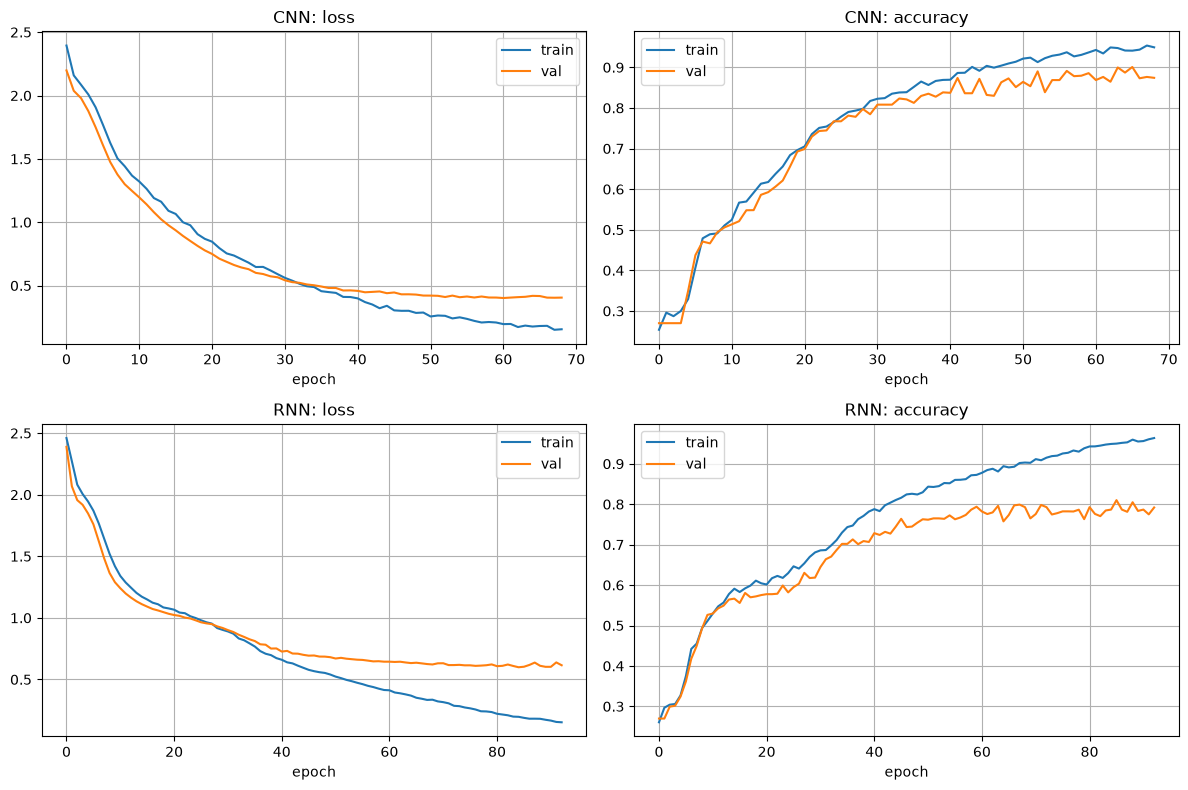

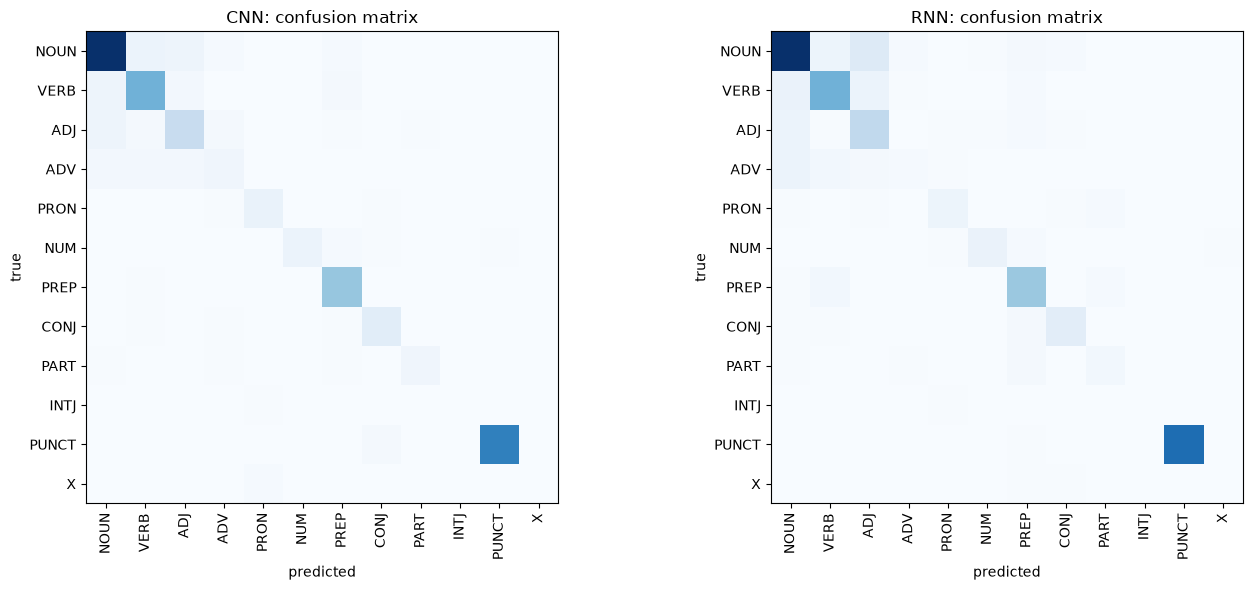

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, (name, hist) in enumerate([('CNN', cnn_history), ('RNN', rnn_history)]):
    axes[row, 0].plot(hist.history['loss'], label='train')
    axes[row, 0].plot(hist.history['val_loss'], label='val')
    axes[row, 0].set_title(f'{name}: loss')
    axes[row, 1].plot(hist.history['masked_accuracy'], label='train')
    axes[row, 1].plot(hist.history['val_masked_accuracy'], label='val')
    axes[row, 1].set_title(f'{name}: accuracy')
    for ax in axes[row]:
        ax.set_xlabel('epoch')
        ax.legend()
        ax.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'training_history.png'), dpi=120)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, t, p) in zip(axes, [('CNN', cnn_true, cnn_pred), ('RNN', rnn_true, rnn_pred)]):
    cm = confusion_matrix(t, p, labels=range(len(TAGS)))
    ax.imshow(cm, cmap='Blues')
    ax.set_xticks(range(len(TAGS)), TAGS, rotation=90)
    ax.set_yticks(range(len(TAGS)), TAGS)
    ax.set_xlabel('predicted')
    ax.set_ylabel('true')
    ax.set_title(f'{name}: confusion matrix')
plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'confusion_matrices.png'), dpi=120)


## Предсказание для нового предложения

In [11]:
def tag_sentence(text, model):
    """Возвращает для каждого слова тег и вектор уверенности по всем частям речи."""
    tokens = TOKEN_RE.findall(text)
    result = []
    for start in range(0, len(tokens), MAX_WORDS):
        chunk = tokens[start:start + MAX_WORDS]
        proba = model.predict(encode_words([chunk], char2id), verbose=0)[0]
        for j, word in enumerate(chunk):
            result.append((word, TAGS[int(proba[j].argmax())], proba[j]))
    return result


def show(text):
    cnn_res = tag_sentence(text, cnn_model)
    rnn_res = tag_sentence(text, rnn_model)
    print(f'\n{"слово":<15}{"CNN":<18}{"RNN":<18}{"pymorphy3 (эталон)"}')
    print('-' * 65)
    for (word, c_tag, c_vec), (_, r_tag, r_vec) in zip(cnn_res, rnn_res):
        print(f'{word:<15}{c_tag + f" {c_vec.max():.2f}":<18}{r_tag + f" {r_vec.max():.2f}":<18}{pos_tag(word)}')


## Демонстрация на новых предложениях

Чтобы разобрать своё предложение, добавьте в новую ячейку вызов `show('...')`.

In [12]:
show('Маша быстро пошла в лес за грибами, а медведь спал в избушке.')



слово          CNN               RNN               pymorphy3 (эталон)
-----------------------------------------------------------------
Маша           NOUN 0.78         NOUN 0.89         NOUN
быстро         NOUN 0.50         NOUN 0.47         ADV
пошла          VERB 0.99         VERB 0.98         VERB
в              PREP 1.00         PREP 0.99         PREP
лес            NOUN 0.95         NOUN 0.97         NOUN
за             PREP 0.99         PREP 1.00         PREP
грибами        NOUN 1.00         NOUN 1.00         NOUN
,              PUNCT 1.00        PUNCT 1.00        PUNCT
а              CONJ 0.95         CONJ 0.53         CONJ
медведь        NOUN 1.00         NOUN 0.81         NOUN
спал           VERB 0.91         VERB 0.99         VERB
в              PREP 1.00         PREP 0.99         PREP
избушке        NOUN 1.00         NOUN 0.99         NOUN
.              PUNCT 1.00        PUNCT 1.00        PUNCT


In [13]:
show('Иванов купил новый автомобиль и быстро уехал домой.')



слово          CNN               RNN               pymorphy3 (эталон)
-----------------------------------------------------------------
Иванов         NOUN 0.79         NOUN 0.94         NOUN
купил          NOUN 0.69         VERB 0.96         VERB
новый          ADJ 0.99          ADJ 0.91          ADJ
автомобиль     VERB 0.51         NOUN 0.75         NOUN
и              CONJ 0.99         CONJ 0.95         CONJ
быстро         NOUN 0.69         NOUN 0.73         ADV
уехал          VERB 1.00         VERB 1.00         VERB
домой          ADJ 0.85          ADV 0.43          ADV
.              PUNCT 1.00        PUNCT 1.00        PUNCT
